In [1]:
#1 Master Import Cell

# Core Python & Data Handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Machine Learning
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

# Utility
import warnings
import textwrap


In [2]:
#2 Generating our dataset
def generate_material_dataset(n_rows=1000, seed=42):
    """
    Generate a synthetic dataset for material properties
    with missing values and ~4% outliers (scattered).
    Reproducible via fixed random seed.
    """

    np.random.seed(seed)

    # Generate synthetic data with realistic ranges
    data = {
        "Tensile_Strength": np.random.uniform(200, 2000, n_rows),  # MPa
        "Yield_Strength": np.random.uniform(100, 1500, n_rows),    # MPa
        "Hardness": np.random.uniform(50, 700, n_rows),            # Vickers HV
        "Density": np.random.uniform(1.5, 8.5, n_rows),            # g/cm³
        "Thermal_Conductivity": np.random.uniform(5, 400, n_rows), # W/mK
        "Elasticity": np.random.uniform(10, 400, n_rows),          # GPa
    }

    df = pd.DataFrame(data)

    # Define number of missing values per column
    missing_counts = {
        "Tensile_Strength": 30,
        "Yield_Strength": 40,
        "Hardness": 50,
        "Density": 20,
        "Thermal_Conductivity": 60,
        "Elasticity": 35,
    }

    # Scatter missing values
    for col, n_missing in missing_counts.items():
        missing_indices = np.random.choice(df.index, n_missing, replace=False)
        df.loc[missing_indices, col] = np.nan

    # Add Outliers (≈4% of total values = 240)
    total_outliers = int(0.04 * df.size)  # 240 for 1000x6
    added_outliers = 0

    while added_outliers < total_outliers:
        for col in df.columns:
            # Random 3–10 outliers per column per pass
            n_outliers = np.random.randint(3, 11)

            # Don’t exceed total target
            if added_outliers + n_outliers > total_outliers:
                n_outliers = total_outliers - added_outliers

            if n_outliers <= 0:
                break

            # Choose indices that are NOT NaN for this column (preserve NaNs)
            available_indices = df.index[df[col].notna()]
            if len(available_indices) == 0:
                continue  # no place to add outliers in this column

            # If not enough available indices, sample with replacement of the available set
            replace_flag = n_outliers > len(available_indices)
            outlier_indices = np.random.choice(available_indices, size=n_outliers, replace=replace_flag)

            # Corrected indentation for the following if/elif block
            if col == "Tensile_Strength":
                df.loc[outlier_indices, col] = np.random.uniform(5000, 7000, n_outliers)
            elif col == "Yield_Strength":
                df.loc[outlier_indices, col] = np.random.uniform(3000, 5000, n_outliers)
            elif col == "Hardness":
                df.loc[outlier_indices, col] = np.random.uniform(1500, 2500, n_outliers)
            elif col == "Density":
                df.loc[outlier_indices, col] = np.random.uniform(15, 25, n_outliers)
            elif col == "Thermal_Conductivity":
                df.loc[outlier_indices, col] = np.random.uniform(1000, 1500, n_outliers)
            elif col == "Elasticity":
                df.loc[outlier_indices, col] = np.random.uniform(1200, 2000, n_outliers)

            added_outliers += n_outliers
            if added_outliers >= total_outliers:
                break

    # print(f"Total outliers added: {added_outliers}")
    return df

# Usage
df = generate_material_dataset()

In [3]:
#3 The Features
display(df.head())
print("Shape:", df.shape)

,Tensile_Strength,Yield_Strength,Hardness,Density,Thermal_Conductivity,Elasticity
0,874.172214,4960.280577,220.108694,6.208921,230.938372,163.517853
1,1911.285752,858.661326,2235.117188,7.076770,323.145770,194.639907
2,1517.589095,1322.124170,639.065477,3.253275,305.263567,343.273483
3,1277.585272,1125.114841,212.205030,5.874119,65.790462,142.601711
4,480.833553,NaN,226.767322,5.502222,63.953541,349.163377


Shape: (1000, 6)


In [4]:
#4
print(df.columns.tolist())
print(df.head())
print(df.info())
print(df.describe())


['Tensile_Strength', 'Yield_Strength', 'Hardness', 'Density', 'Thermal_Conductivity', 'Elasticity']
   Tensile_Strength  Yield_Strength     Hardness   Density  \
0        874.172214     4960.280577   220.108694  6.208921   
1       1911.285752      858.661326  2235.117188  7.076770   
2       1517.589095     1322.124170   639.065477  3.253275   
3       1277.585272     1125.114841   212.205030  5.874119   
4        480.833553             NaN   226.767322  5.502222   

   Thermal_Conductivity  Elasticity  
0            230.938372  163.517853  
1            323.145770  194.639907  
2            305.263567  343.273483  
3             65.790462  142.601711  
4             63.953541  349.163377  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Tensile_Strength      970 non-null    float64
 1   Yield_Strength        960 non-null  

In [5]:
#5 Checking missing values first
print("\nMissing values per column:\n", df.isna().sum())


Missing values per column:
 Tensile_Strength        30
Yield_Strength          40
Hardness                50
Density                 20
Thermal_Conductivity    60
Elasticity              35
dtype: int64


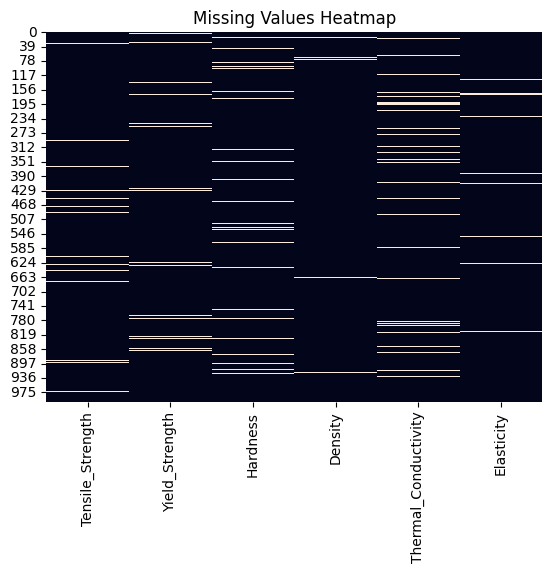

In [6]:
#6 Visualize missingness before imputation
sns.heatmap(df.isnull(), cbar=False)
plt.title('Missing Values Heatmap')
plt.show()

In [7]:
#7 Column-specific imputations

# (a) Density → Mean Imputation
df["Density"] = df["Density"].fillna(df["Density"].mean())

# (b) Thermal Conductivity → Median Imputation
df["Thermal_Conductivity"] = df["Thermal_Conductivity"].fillna(df["Thermal_Conductivity"].median())

# (c) Hardness → Median Imputation
df["Hardness"] = df["Hardness"].fillna(df["Hardness"].median())

# (d) Yield Strength → Regression on Tensile Strength
if df["Yield_Strength"].isna().sum() > 0:
    train = df[df["Yield_Strength"].notna()].copy()
    test = df[df["Yield_Strength"].isna()].copy()
    if not test.empty:
        # Drop rows with NaN in Tensile_Strength
        train = train.dropna(subset=["Tensile_Strength"])
        if not train.empty:
            model = LinearRegression()
            model.fit(train[["Tensile_Strength"]], train["Yield_Strength"])
            # Simple imputation for missing Tensile_Strength in test before prediction
            test["Tensile_Strength"] = test["Tensile_Strength"].fillna(train["Tensile_Strength"].mean())
            df.loc[df["Yield_Strength"].isna(), "Yield_Strength"] = model.predict(test[["Tensile_Strength"]])
        else:
            print("Not enough data in 'Tensile_Strength' to train the regression model.")

# (e) Elasticity → Median Imputation
df["Elasticity"] = df["Elasticity"].fillna(df["Elasticity"].median())

# Final catch-all KNN cleanup (guarantees no NaN remains)
imputer = KNNImputer(n_neighbors=5)
df[:] = imputer.fit_transform(df)

# Verify
print("Missing values after imputation:\n", df.isna().sum())

Missing values after imputation:
 Tensile_Strength        0
Yield_Strength          0
Hardness                0
Density                 0
Thermal_Conductivity    0
Elasticity              0
dtype: int64


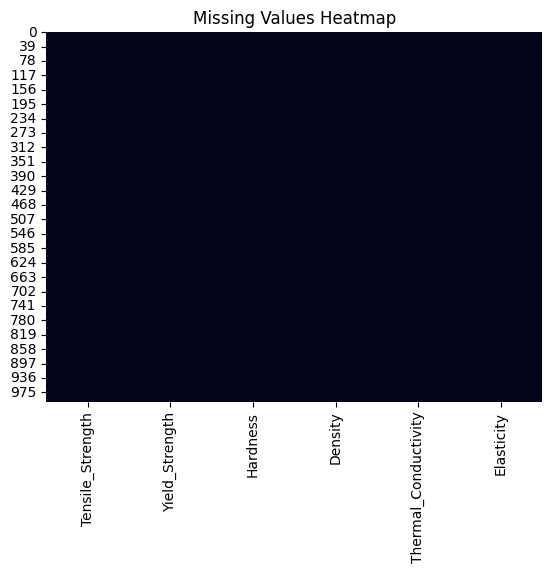

In [8]:
#8 Visualize missingness after imputation
sns.heatmap(df.isnull(), cbar=False)
plt.title('Missing Values Heatmap')
plt.show()

In [9]:
#9 Outlier Dectection
# IQR METHOD
def detect_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return series[(series < lower_bound) | (series > upper_bound)]

# Z-SCORE METHOD
def detect_outliers_zscore(series, threshold=3):
    mean = series.mean()
    std = series.std()
    z_scores = (series - mean) / std
    return series[(z_scores < -threshold) | (z_scores > threshold)]

# Print outlier counts per feature
print(" IQR Outliers Count ")
for col in df.columns:
    print(f"{col}: {len(detect_outliers_iqr(df[col]))}")

print("\n Z-Score Outliers Count ")
for col in df.columns:
    print(f"{col}: {len(detect_outliers_zscore(df[col]))}")

 IQR Outliers Count 
Tensile_Strength: 40
Yield_Strength: 39
Hardness: 46
Density: 38
Thermal_Conductivity: 41
Elasticity: 31

 Z-Score Outliers Count 
Tensile_Strength: 40
Yield_Strength: 36
Hardness: 41
Density: 32
Thermal_Conductivity: 41
Elasticity: 31


In [10]:
#10 Function to cap outliers using IQR
def cap_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return np.clip(series, lower_bound, upper_bound)

# Apply to all columns
df_iqr = df.copy()
for col in df_iqr.columns:
    df_iqr[col] = cap_outliers_iqr(df_iqr[col])

print("IQR Capping Completed ✅")

IQR Capping Completed ✅


In [11]:
#11 Function to cap outliers using Z-Score
def cap_outliers_zscore(series, threshold=3):
    mean = series.mean()
    std = series.std()
    lower_bound = mean - threshold * std
    upper_bound = mean + threshold * std
    return np.clip(series, lower_bound, upper_bound)

# Apply to all columns
df_zscore = df.copy()
for col in df_zscore.columns:
    df_zscore[col] = cap_outliers_zscore(df_zscore[col])

print("Z-Score Capping Completed ✅")

Z-Score Capping Completed ✅


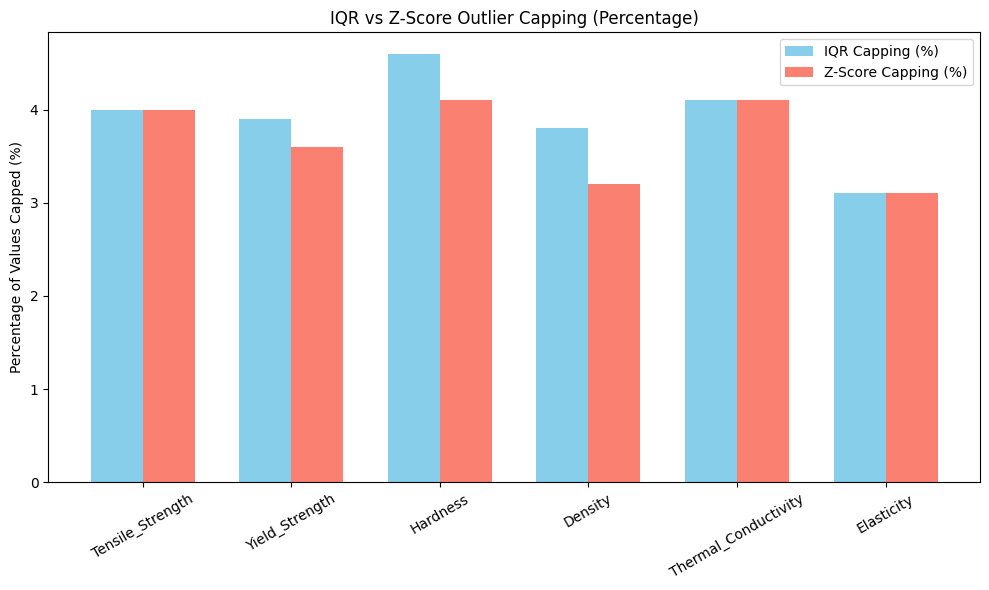

In [12]:
#12 Helper function to compare IQR and Z-Score Outlier Capping
def compare_capping(original, capped):
    """
    Counts how many values were changed after capping.
    """
    return (original != capped).sum()

# Calculate changes for all columns
iqr_changes = [compare_capping(df[col], df_iqr[col]) for col in df.columns]
z_changes = [compare_capping(df[col], df_zscore[col]) for col in df.columns]


iqr_perc = [c / len(df) * 100 for c in iqr_changes]
z_perc   = [c / len(df) * 100 for c in z_changes]

features = df.columns.tolist()
x = np.arange(len(features))
bar_width = 0.35

plt.figure(figsize=(10,6))
plt.bar(x - bar_width/2, iqr_perc, width=bar_width, label="IQR Capping (%)", color="skyblue")
plt.bar(x + bar_width/2, z_perc, width=bar_width, label="Z-Score Capping (%)", color="salmon")

plt.xticks(x, features, rotation=30)
plt.ylabel("Percentage of Values Capped (%)")
plt.title("IQR vs Z-Score Outlier Capping (Percentage)")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
#13 Use cleaned dataset after outlier capping
df_cleaned = df_iqr.copy()   # OR df_zscore.copy()
scaler = StandardScaler()
# Fit scaler on the cleaned data BEFORE adding the Cluster column
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_cleaned),
    columns=df_cleaned.columns
)
df_with_clusters = None

print(df_scaled.head())

   Tensile_Strength  Yield_Strength  Hardness   Density  Thermal_Conductivity  \
0         -0.467519        2.876403 -0.831544  0.405974              0.103514   
1          1.143033       -0.035725  2.785540  0.767993              0.797324   
2          0.531655        0.922484  1.021602 -0.826960              0.662771   
3          0.158948        0.515167 -0.866504  0.266313             -1.139133   
4         -1.078341        0.132046 -0.802092  0.111178             -1.152955   

   Elasticity  
0   -0.419966  
1   -0.177809  
2    0.978689  
3   -0.582712  
4    1.024517  


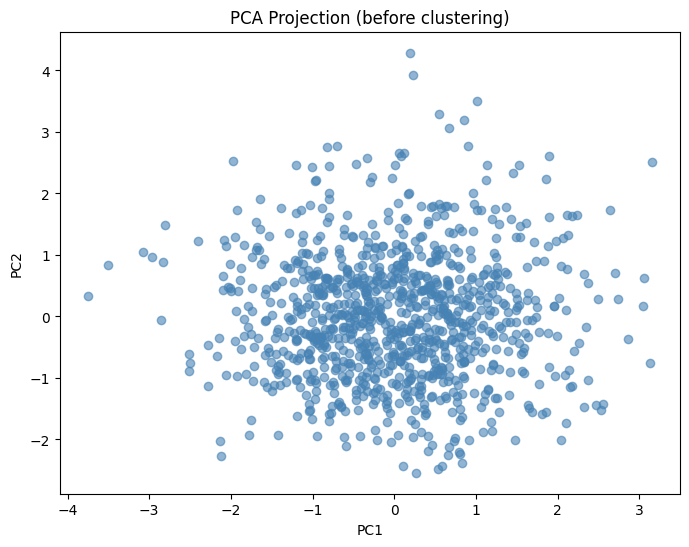

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


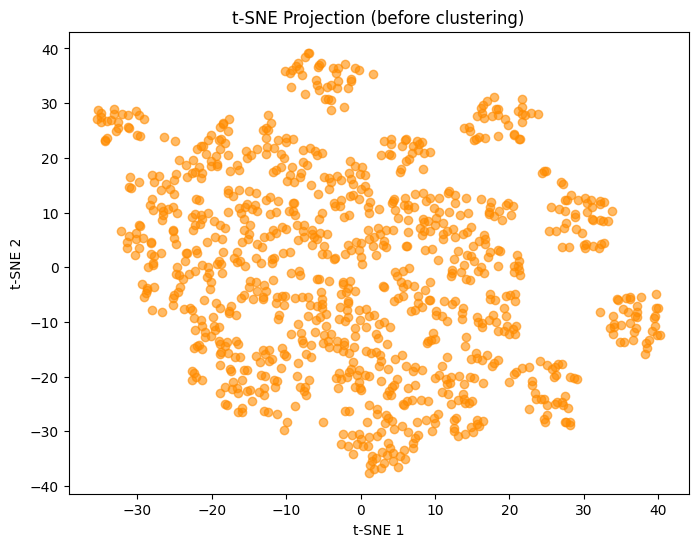

In [14]:
#14 PCA and t-SNE on scaled CLEANED dataset

# a: PCA (deterministic)
pca = PCA(n_components=2, svd_solver='full', random_state=42)  # svd_solver='full' ensures stability
df_pca = pca.fit_transform(df_scaled)

plt.figure(figsize=(8,6))
plt.scatter(df_pca[:,0], df_pca[:,1], alpha=0.6, color="steelblue")
plt.title("PCA Projection (before clustering)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# b: t-SNE (stochastic but fixed with random_state)
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000, init="random",learning_rate="auto")
df_tsne = tsne.fit_transform(df_scaled)

plt.figure(figsize=(8,6))
plt.scatter(df_tsne[:,0], df_tsne[:,1], alpha=0.6, color="darkorange")
plt.title("t-SNE Projection (before clustering)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

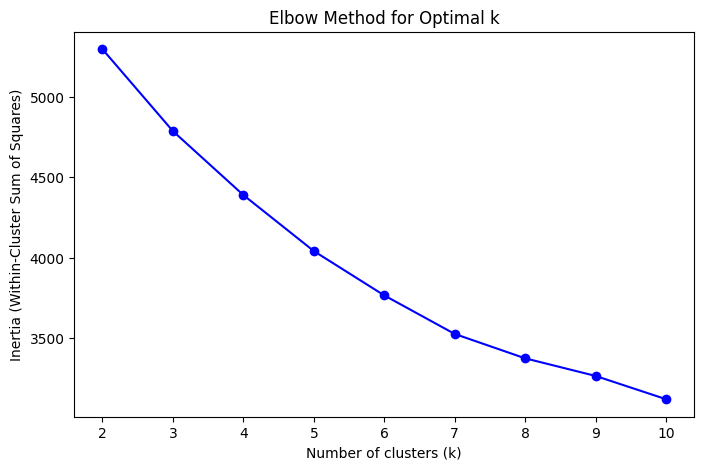

In [15]:
#15 Find optimal k (Elbow Method)
inertia = []
K_range = range(2, 11)  # test k = 2 to 10

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K_range, inertia, 'bo-')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.title("Elbow Method for Optimal k")
plt.show()

In [16]:
#16 Evaluate with Silhouette Score
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_scaled)
    sil_score = silhouette_score(df_scaled, labels)
    print(f"k={k}, Silhouette Score={sil_score:.4f}")

k=2, Silhouette Score=0.1201
k=3, Silhouette Score=0.1157
k=4, Silhouette Score=0.1164
k=5, Silhouette Score=0.1190
k=6, Silhouette Score=0.1247
k=7, Silhouette Score=0.1282
k=8, Silhouette Score=0.1255
k=9, Silhouette Score=0.1193
k=10, Silhouette Score=0.1334


In [17]:
#17 Fit Final KMeans
optimal_k = 4  # <-- replace with best k from Elbow/Silhouette
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(df_scaled)
df_scaled["Cluster"] = clusters

In [18]:
#18 Define descriptive labels ONCE (reuse everywhere)
cluster_labels = {
    0: "0 - Metals/Alloys (General-Purpose)",
    1: "1 - Superalloys (High Strength)",
    2: "2 - Ceramic Composites / Hard Alloys",
    3: "3 - Elastic Lightweight Alloys"
}

/tmp/ipython-input-2240783857.py:34: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_plot = df_with_clusters.groupby("Cluster", group_keys=False).apply(


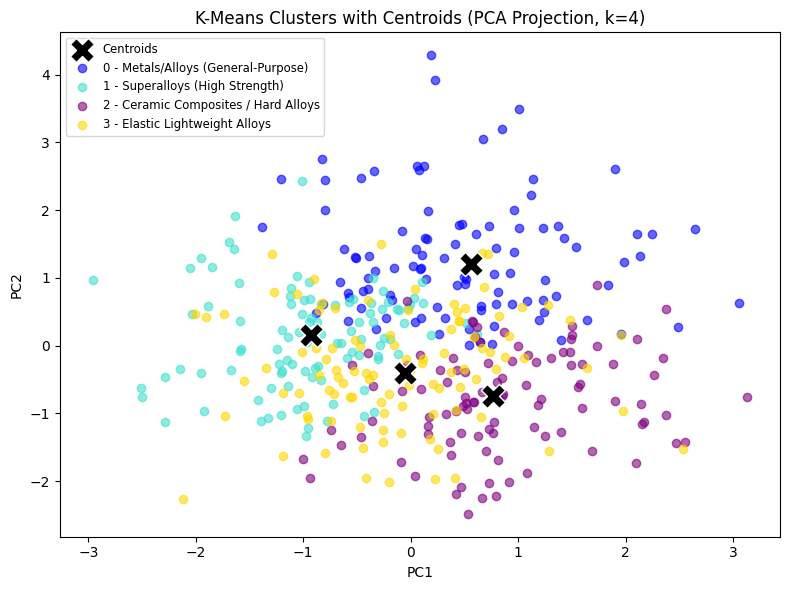

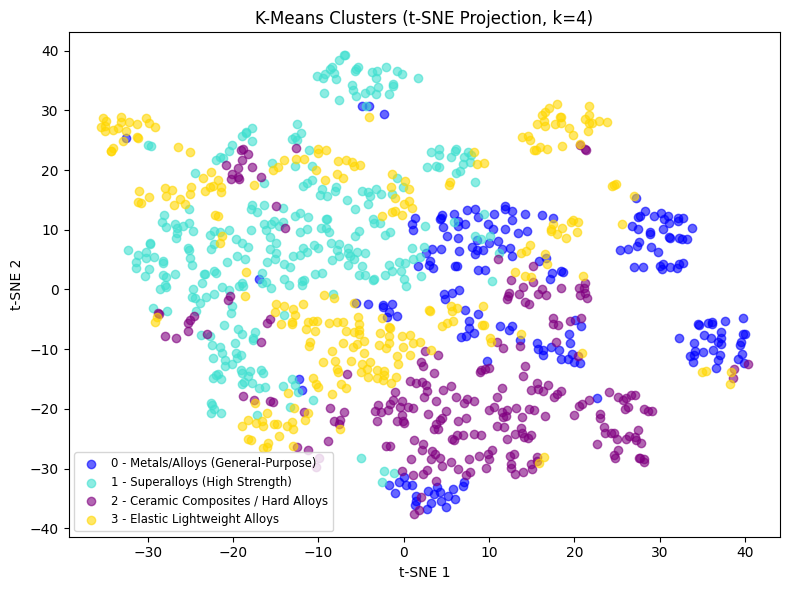

In [19]:
# 19: Robust KMeans plotting
# 1) Ensure df_with_clusters exists (create if missing)
if "df_with_clusters" not in globals() or not isinstance(df_with_clusters, pd.DataFrame):
    # Start from cleaned dataset
    df_with_clusters = df_cleaned.copy()
    # Add cluster assignments
    df_with_clusters["Cluster"] = kmeans.labels_
    # Add PCA/t-SNE coords
    df_with_clusters["PC1"] = df_pca[:, 0]
    df_with_clusters["PC2"] = df_pca[:, 1]
    df_with_clusters["TSNE1"] = df_tsne[:, 0]
    df_with_clusters["TSNE2"] = df_tsne[:, 1]
    # Add descriptive labels if available
    if "cluster_labels" in globals():
        df_with_clusters["Cluster_Label"] = df_with_clusters["Cluster"].map(cluster_labels)

# 2) Get unique clusters
unique_clusters = sorted(df_with_clusters["Cluster"].unique())

# 3) Ensure cluster_labels dictionary covers all clusters
for c in unique_clusters:
    if c not in cluster_labels:
        cluster_labels[c] = f"{c} - Cluster {c}"

# 4) Define colors (custom or fallback)
cluster_colors = {0: "blue", 1: "turquoise", 2: "purple", 3: "gold"}
default_color = "gray"

# PCA Cluster Plot with Centroids at Cluster Means (looks logical)

plt.figure(figsize=(8,6))

# Reduce sample size for plotting (balanced per cluster)
df_plot = df_with_clusters.groupby("Cluster", group_keys=False).apply(
    lambda x: x.sample(min(len(x), 100), random_state=42)  # up to 100 points per cluster
)

# Define centroids as cluster means in PCA space
centroids_pca = df_with_clusters.groupby("Cluster")[["PC1", "PC2"]].mean().values

# Plot centroids first
plt.scatter(centroids_pca[:,0], centroids_pca[:,1],
            marker="X", s=300, c="black", label="Centroids",
            edgecolor='w', zorder=3)

# Plot reduced set of points
for cluster_num in unique_clusters:
    subset = df_plot.loc[df_plot["Cluster"] == cluster_num]
    label = cluster_labels.get(cluster_num, f"{cluster_num} - Cluster {cluster_num}")
    plt.scatter(subset["PC1"], subset["PC2"], label=label, alpha=0.6,
                color=cluster_colors.get(cluster_num, default_color), zorder=2)

plt.title(f"K-Means Clusters with Centroids (PCA Projection, k={len(unique_clusters)})")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend(loc="best", fontsize="small")
plt.tight_layout()
plt.show()

# t-SNE Cluster Plot with Labels
plt.figure(figsize=(8,6))
for cluster_num in unique_clusters:
    subset = df_with_clusters.loc[df_with_clusters["Cluster"] == cluster_num]
    label = cluster_labels.get(cluster_num, f"{cluster_num} - Cluster {cluster_num}")
    plt.scatter(subset["TSNE1"], subset["TSNE2"], label=label, alpha=0.6,
                color=cluster_colors.get(cluster_num, default_color))

plt.title(f"K-Means Clusters (t-SNE Projection, k={len(unique_clusters)})")
plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
plt.legend(loc="best", fontsize="small")
plt.tight_layout()
plt.show()

In [20]:
#20 Final Cluster Profiling

# Start from the CLEANED dataset
df_with_clusters = df_cleaned.copy()

# Add numeric cluster assignments from KMeans
df_with_clusters["Cluster"] = kmeans.labels_

# 3. Add PCA & t-SNE coordinates (from earlier computations)
df_with_clusters["PC1"] = df_pca[:, 0]
df_with_clusters["PC2"] = df_pca[:, 1]
df_with_clusters["TSNE1"] = df_tsne[:, 0]
df_with_clusters["TSNE2"] = df_tsne[:, 1]

df_with_clusters["Cluster_Label"] = df_with_clusters["Cluster"].map(cluster_labels)

# Sanity checks
print("Shape of df_with_clusters:", df_with_clusters.shape)
print("Cluster counts:\n", df_with_clusters["Cluster"].value_counts())
print("NaNs per column:\n", df_with_clusters.isna().sum())
assert len(df_with_clusters) == len(df_pca) == len(df_tsne), "Mismatch in shapes!"

# Cluster profiling with descriptive labels
cluster_profile_lbl = df_with_clusters.groupby("Cluster_Label").mean(numeric_only=True).round(2)
cluster_profile_lbl["Count"] = (
    df_with_clusters["Cluster_Label"].value_counts()
    .reindex(cluster_labels.values())
    .fillna(0)
    .astype(int)
)

Shape of df_with_clusters: (1000, 12)
Cluster counts:
 Cluster
1    303
3    260
2    242
0    195
Name: count, dtype: int64
NaNs per column:
 Tensile_Strength        0
Yield_Strength          0
Hardness                0
Density                 0
Thermal_Conductivity    0
Elasticity              0
Cluster                 0
PC1                     0
PC2                     0
TSNE1                   0
TSNE2                   0
Cluster_Label           0
dtype: int64


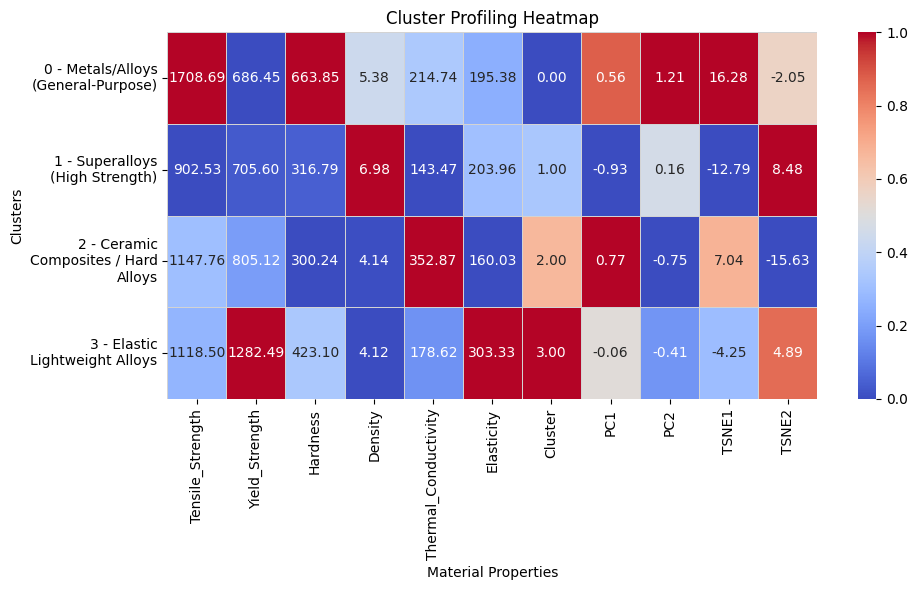

In [21]:
#21 Final Cluster Profiling Heatmap
# quick sanity checks
assert 'df_with_clusters' in globals(), "df_with_clusters not defined"
assert len(df_with_clusters) == len(df_pca) == len(df_tsne), "Mismatch in shapes: df_with_clusters / df_pca / df_tsne"
assert 'kmeans' in globals() and hasattr(kmeans,'cluster_centers_'), "kmeans not fitted"

# Prepare a numeric DataFrame (exclude Count)
profile_vals = cluster_profile_lbl.drop(columns="Count")

# Wrap the index labels to max width (e.g., 20 chars per line)
wrapped_index = ["\n".join(textwrap.wrap(str(lbl), 20)) for lbl in profile_vals.index]
profile_wrapped = profile_vals.copy()
profile_wrapped.index = wrapped_index

# Normalize for color scaling (0..1 per column)
profile_norm = (profile_wrapped - profile_wrapped.min()) / (profile_wrapped.max() - profile_wrapped.min())

# Plot heatmap with wrapped labels (annotated with actual means)
plt.figure(figsize=(10, 6))
sns.heatmap(
    profile_norm,
    annot=profile_wrapped,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    linewidths=0.5,
    linecolor='lightgray'
)

plt.title("Cluster Profiling Heatmap")
plt.xlabel("Material Properties")
plt.ylabel("Clusters")
plt.tight_layout()
plt.show()

In [22]:
#22 Export final clustered dataset
df_with_clusters.to_csv("material_clusters.csv", index=False)
print("✅ Final clustered dataset exported as 'material_clusters.csv'")
import joblib
joblib.dump(scaler, "scaler.joblib")
joblib.dump(pca, "pca.joblib")
joblib.dump(kmeans, "kmeans.joblib")
print("Saved CSV and joblib model files.")

✅ Final clustered dataset exported as 'material_clusters.csv'
Saved CSV and joblib model files.


In [23]:
#23
# Diagnostic (feature mismatch check)
from pprint import pprint

# Inspect the training/test and model shapes if they exist
print("Variables present (quick):", [v for v in ['df_cleaned','df_scaled','df_with_clusters','X_train','X_test','best_models'] if v in globals()])

print("\n df_cleaned columns")
if 'df_cleaned' in globals() and isinstance(df_cleaned, pd.DataFrame):
    pprint(df_cleaned.columns.tolist())
else:
    raise RuntimeError("df_cleaned not found or not a DataFrame. Run earlier cleaning cells.")

print("\n df_scaled shape/cols (if DataFrame)")
if 'df_scaled' in globals():
    print(type(df_scaled), getattr(df_scaled, "shape", None))
    if isinstance(df_scaled, pd.DataFrame):
        pprint(df_scaled.columns.tolist())

# If best_models exists, inspect one model's expected features
if 'best_models' in globals() and isinstance(best_models, dict) and len(best_models) > 0:
    name = next(iter(best_models))  # gets the first key safely
    model = best_models[name]

    name = list(best_models.keys())[0]
    model = best_models[name]
    print(f"\nFound best_models entry: {name} (type: {type(model).__name__})")
    print("model.n_features_in_:", getattr(model, "n_features_in_", None))
else:
    print("\nNo existing trained best_models found in workspace. Proceeding to retrain (next cell).")


Variables present (quick): ['df_cleaned', 'df_scaled', 'df_with_clusters']

 df_cleaned columns
['Tensile_Strength',
 'Yield_Strength',
 'Hardness',
 'Density',
 'Thermal_Conductivity',
 'Elasticity']

 df_scaled shape/cols (if DataFrame)
<class 'pandas.core.frame.DataFrame'> (1000, 7)
['Tensile_Strength',
 'Yield_Strength',
 'Hardness',
 'Density',
 'Thermal_Conductivity',
 'Elasticity',
 'Cluster']

No existing trained best_models found in workspace. Proceeding to retrain (next cell).


In [24]:
#24
# Retrain models on explicit feature
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import make_scorer, f1_score

# Use explicit feature list from df_cleaned to avoid accidental extra cols
features = df_cleaned.columns.tolist()
print("Using features:", features)

# Build X (scaled) and y (cluster labels)
if isinstance(df_scaled, pd.DataFrame):
    X_all = df_scaled[features].copy()
else:
    # if df_scaled is numpy array, create DataFrame in same column order
    X_all = pd.DataFrame(df_scaled, columns=features)

y_all = df_with_clusters["Cluster"].astype(int).copy()

# Train/test split (80/20 stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=42
)
print("X_train, X_test shapes:", X_train.shape, X_test.shape)

# Define models and grids
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
estimators = {
    "LogisticRegression": LogisticRegression(multi_class="multinomial", solver="saga", max_iter=5000, random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}
param_grids = {
    "LogisticRegression": {"C": [0.01, 0.1, 1.0, 5.0], "penalty": ["l2"]},
    "RandomForest": {"n_estimators": [100, 250], "max_depth": [6, 12, None], "min_samples_split": [2, 5]},
    "SVM": {"C": [0.1, 1.0, 5.0], "kernel": ["rbf"], "gamma": ["scale", "auto"]}
}

scorer = make_scorer(f1_score, average="macro")

best_models = {}
cv_results_summary = {}
for name, estimator in estimators.items():
    print(f"\nGridSearchCV for {name} ...")
    grid = GridSearchCV(estimator, param_grids[name], cv=cv, scoring=scorer, n_jobs=-1, verbose=1, return_train_score=True)
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_
    cv_results_summary[name] = grid.cv_results_
    print(f"-> {name} best params: {grid.best_params_}")
    print(f"-> {name} best CV f1_macro: {grid.best_score_:.4f}")

# keep X_train / X_test / y_train / y_test in workspace for evaluation
print("\nRetraining completed. Best models stored in `best_models`.")

features = df_cleaned.columns.tolist()

Using features: ['Tensile_Strength', 'Yield_Strength', 'Hardness', 'Density', 'Thermal_Conductivity', 'Elasticity']
X_train, X_test shapes: (800, 6) (200, 6)

GridSearchCV for LogisticRegression ...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


-> LogisticRegression best params: {'C': 5.0, 'penalty': 'l2'}
-> LogisticRegression best CV f1_macro: 0.9859

GridSearchCV for RandomForest ...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
-> RandomForest best params: {'max_depth': 12, 'min_samples_split': 5, 'n_estimators': 250}
-> RandomForest best CV f1_macro: 0.8560

GridSearchCV for SVM ...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
-> SVM best params: {'C': 5.0, 'gamma': 'scale', 'kernel': 'rbf'}
-> SVM best CV f1_macro: 0.9434

Retraining completed. Best models stored in `best_models`.


 Overfitting Check (Train vs Test) 
LogisticRegression - Train Accuracy: 0.996, Test Accuracy: 0.995
RandomForest - Train Accuracy: 1.000, Test Accuracy: 0.815
SVM - Train Accuracy: 0.993, Test Accuracy: 0.930

 Final Evaluation on Test Set 

< LogisticRegression >
Accuracy: 0.995
Classification Report:
                                       precision    recall  f1-score   support

 0 - Metals/Alloys (General-Purpose)       1.00      0.97      0.99        39
     1 - Superalloys (High Strength)       0.98      1.00      0.99        61
2 - Ceramic Composites / Hard Alloys       1.00      1.00      1.00        48
      3 - Elastic Lightweight Alloys       1.00      1.00      1.00        52

                            accuracy                           0.99       200
                           macro avg       1.00      0.99      0.99       200
                        weighted avg       1.00      0.99      0.99       200



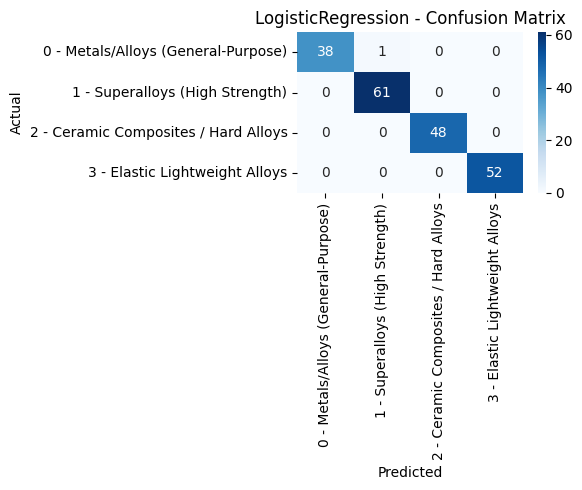

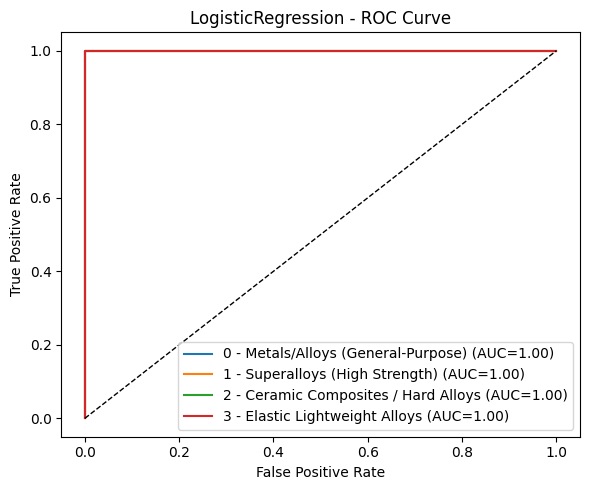

< RandomForest >
Accuracy: 0.815
Classification Report:
                                       precision    recall  f1-score   support

 0 - Metals/Alloys (General-Purpose)       0.85      0.85      0.85        39
     1 - Superalloys (High Strength)       0.83      0.85      0.84        61
2 - Ceramic Composites / Hard Alloys       0.90      0.73      0.80        48
      3 - Elastic Lightweight Alloys       0.73      0.83      0.77        52

                            accuracy                           0.81       200
                           macro avg       0.82      0.81      0.82       200
                        weighted avg       0.82      0.81      0.82       200



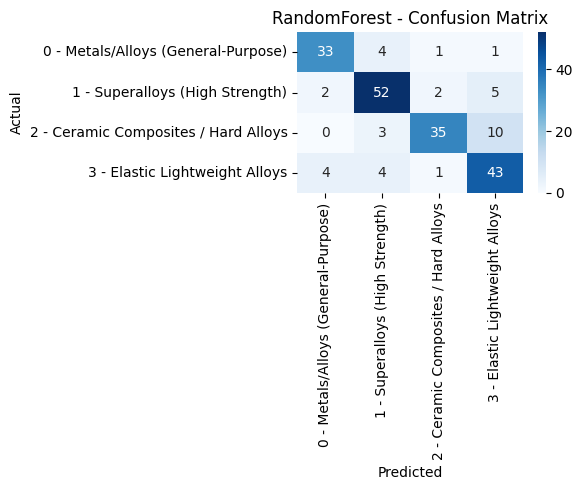

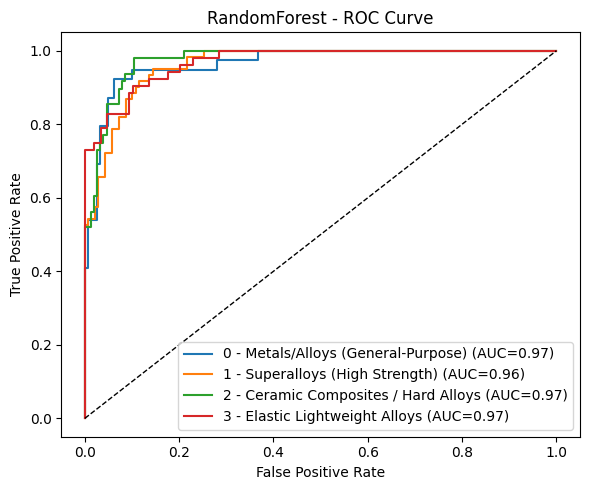

< SVM >
Accuracy: 0.93
Classification Report:
                                       precision    recall  f1-score   support

 0 - Metals/Alloys (General-Purpose)       0.95      0.90      0.92        39
     1 - Superalloys (High Strength)       0.93      0.93      0.93        61
2 - Ceramic Composites / Hard Alloys       1.00      0.92      0.96        48
      3 - Elastic Lightweight Alloys       0.86      0.96      0.91        52

                            accuracy                           0.93       200
                           macro avg       0.94      0.93      0.93       200
                        weighted avg       0.93      0.93      0.93       200



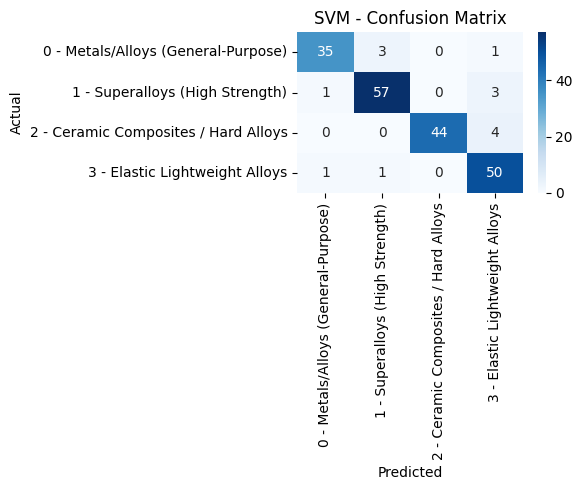

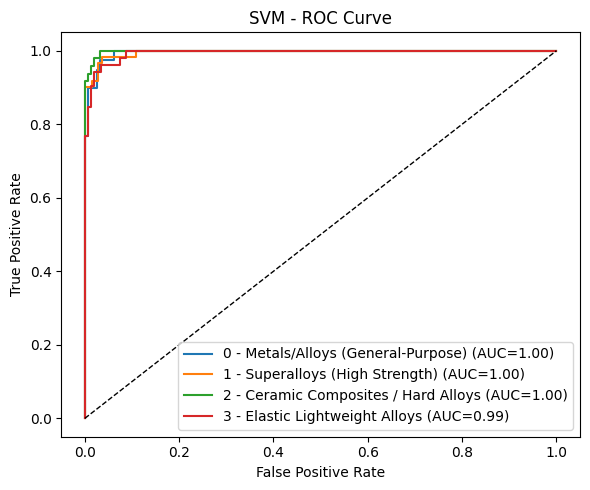


 Performance Summary (macro averages) 



,F1_macro,Precision_macro,Recall_macro,Accuracy
LogisticRegression,0.995,0.996,0.994,0.995
RandomForest,0.816,0.824,0.814,0.815
SVM,0.930,0.936,0.928,0.930


In [25]:
# 25
# Final Model Evaluation, Confusion Matrices, ROC & Overfitting Check
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# Ensure consistent order of clusters
labels_sorted = sorted(df_with_clusters["Cluster"].unique())
label_names = [cluster_labels[c] for c in labels_sorted]

# Confusion matrix plotting helper
def plot_confusion(cm, names, title, save_as=None):
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=names, yticklabels=names)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()

# Store results
results_summary = {}

print(" Overfitting Check (Train vs Test) ")
for name, model in best_models.items():
    y_train_pred = model.predict(X_train)
    train_acc = accuracy_score(y_train, y_train_pred)

    y_test_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, y_test_pred)

    print(f"{name} - Train Accuracy: {train_acc:.3f}, Test Accuracy: {test_acc:.3f}")

print("\n Final Evaluation on Test Set \n")
for name, model in best_models.items():
    print(f"< {name} >")

    # Predictions
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True, target_names=label_names)
    cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

    results_summary[name] = {"accuracy": acc, "report": report, "cm": cm}

    # Print classification report
    print("Accuracy:", round(acc, 3))
    print("Classification Report:\n", classification_report(y_test, y_pred, target_names=label_names))

    # Plot seaborn confusion matrix
    plot_confusion(cm, label_names, title=f"{name} - Confusion Matrix",
                   save_as=f"{name}_confusion_matrix.png")

    # ROC Curve (one-vs-rest for multiclass)
    y_test_bin = label_binarize(y_test, classes=labels_sorted)
    y_score = model.predict_proba(X_test)
    fpr, tpr, roc_auc = {}, {}, {}
    for i, cls in enumerate(labels_sorted):
        fpr[cls], tpr[cls], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[cls] = auc(fpr[cls], tpr[cls])

    # Plot ROC
    plt.figure(figsize=(6,5))
    for i, cls in enumerate(labels_sorted):
        plt.plot(fpr[cls], tpr[cls], label=f"{label_names[i]} (AUC={roc_auc[cls]:.2f})")
    plt.plot([0,1], [0,1], "k--", lw=1)
    plt.title(f"{name} - ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Summary Table (macro averages)
summary_table = pd.DataFrame({
    model: {
        "F1_macro": results_summary[model]["report"]["macro avg"]["f1-score"],
        "Precision_macro": results_summary[model]["report"]["macro avg"]["precision"],
        "Recall_macro": results_summary[model]["report"]["macro avg"]["recall"],
        "Accuracy": results_summary[model]["accuracy"]
    }
    for model in results_summary
}).T.round(3)

print("\n Performance Summary (macro averages) \n")
display(summary_table)

In [26]:
# 26
# Macro AUC summary per model
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = sorted(y_all.unique())
y_test_bin = label_binarize(y_test, classes=classes)

model_auc_summary = {}
for name, model in best_models.items():
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)
    else:
        y_score = model.decision_function(X_test)

    # compute per-class AUC
    roc_auc = {}
    for i, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[cls] = auc(fpr, tpr)

    # macro AUC = mean of per-class AUCs
    macro_auc = np.mean(list(roc_auc.values()))
    model_auc_summary[name] = macro_auc

# Display results as a summary table
auc_table = pd.DataFrame.from_dict(model_auc_summary, orient="index", columns=["Macro AUC"]).round(3)

print("\n Macro AUC Summary (per model)\n")
display(auc_table)


 Macro AUC Summary (per model)



,Macro AUC
LogisticRegression,1.000
RandomForest,0.968
SVM,0.996


In [27]:
# 27
# Model summary and save best model/artifacts

# Ensure results exist
if "results_summary" not in globals():
    raise RuntimeError("`results_summary` not found. Run the evaluation cell before this one.")

summary_rows = []
for name, res in results_summary.items():
    acc = res["accuracy"]
    macro_f1 = res["report"]["macro avg"]["f1-score"]
    macro_auc = model_auc_summary.get(name, float("nan"))
    summary_rows.append({
        "Model": name,
        "Accuracy": acc,
        "Macro F1": macro_f1,
        "Macro AUC": macro_auc
    })

# Summary DataFrame
summary_df = (
    pd.DataFrame(summary_rows)
    .set_index("Model")
    .round(4)
    .sort_values(by="Macro F1", ascending=False)
)

print(" Model comparison summary:\n")
display(summary_df)

# Select best model (by Macro F1 — can change to Macro AUC if desired)
best_name = summary_df.index[0]
best_model = best_models[best_name]
print(f"\n✅ Selected best model: {best_name}")

# Save artifacts
import joblib
joblib.dump(best_model, "best_material_classifier.joblib")
joblib.dump(scaler, "scaler.joblib")
joblib.dump(cluster_labels, "cluster_labels.joblib")
print("💾 Saved best model, scaler, and cluster_labels.")

 Model comparison summary:



,Accuracy,Macro F1,Macro AUC
Model,,,
LogisticRegression,0.995,0.9947,1.0000
SVM,0.930,0.9303,0.9960
RandomForest,0.815,0.8161,0.9682



✅ Selected best model: LogisticRegression
💾 Saved best model, scaler, and cluster_labels.


In [28]:
#28
# Print the best model object
print("✅ Best Model Selected:")
print(best_model)


✅ Best Model Selected:
LogisticRegression(C=5.0, max_iter=5000, multi_class='multinomial',
                   random_state=42, solver='saga')


In [29]:
# 29
# Enhanced Prediction helper with Visualization

def predict_material_cluster(model, new_material_dict, scaler=scaler, features=None, plot=True):
    """
    Predict cluster for a new material sample with optional visualization.

    Parameters:
    - model: trained classifier
    - new_material_dict: dict of feature:value pairs (feature names must match df_cleaned columns)
    - scaler: fitted scaler (e.g., StandardScaler)
    - features: list of feature names; default = df_cleaned.columns order
    - plot: if True, display a bar chart of confidence scores
    """
    if features is None:
        features = df_cleaned.columns.tolist()

    # Build single-row DataFrame with correct feature order
    row = pd.DataFrame([[ new_material_dict.get(f, np.nan) for f in features ]],
                       columns=features)

    # Handle missing values by filling with training means
    if row.isna().sum().sum() > 0:
        row = row.fillna(df_cleaned.mean())

    # Scale input
    if scaler is None:
        raise RuntimeError("Scaler not found. Please define or load the fitted scaler.")
    row_scaled = scaler.transform(row)

    # Predict
    pred = model.predict(row_scaled)

    # Get probabilities or decision function
    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(row_scaled)[0]
    else:
        prob = model.decision_function(row_scaled)
        if prob.ndim == 1:  # binary case
            prob = [prob]

    cluster_num = int(pred[0])
    label = cluster_labels.get(cluster_num, str(cluster_num))

    # Build probability dictionary with labels
    prob_dict = {
        cluster_labels.get(i, str(i)): float(prob[i])
        for i in range(len(prob))
    }

    # Print summary
    print("🔎 Predicting with Logistic Regression")
    print(f"\n📍 Predicted Cluster: {cluster_num} – {label}")
    print("✅ Confidence Scores:")
    for i, score in prob_dict.items():
        print(f"  - {i}: {score:.4f}")

    # Visualization
    if plot:
        plt.figure(figsize=(6,4))
        bars = plt.bar(prob_dict.keys(), prob_dict.values(),
                       color=[cluster_colors.get(i, "gray") for i in range(len(prob_dict))])
        plt.ylabel("Probability")
        plt.title(f"Visualizing Alloy Predictions")
        plt.ylim(0,1.05)
        plt.xticks(rotation=25, ha="right")

        # Annotate bars with exact values
        for bar, value in zip(bars, prob_dict.values()):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.01,
                     f"{value:.2f}", ha="center", va="bottom", fontsize=9)

        plt.tight_layout()
        plt.show()

    return {"cluster": cluster_num, "label": label, "probabilities": prob_dict}

🔎 Predicting with Logistic Regression

📍 Predicted Cluster: 1 – 1 - Superalloys (High Strength)
✅ Confidence Scores:
  - 0 - Metals/Alloys (General-Purpose): 0.0000
  - 1 - Superalloys (High Strength): 0.9121
  - 2 - Ceramic Composites / Hard Alloys: 0.0879
  - 3 - Elastic Lightweight Alloys: 0.0000


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


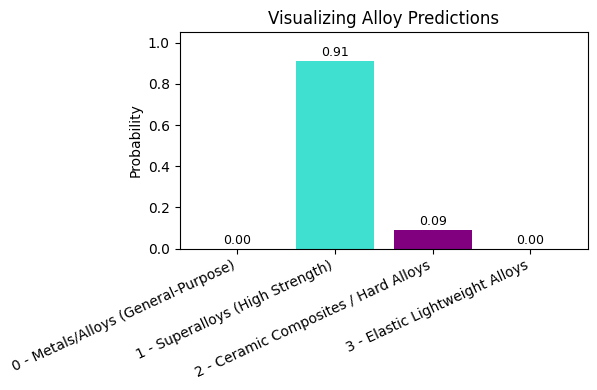

{'cluster': 1, 'label': '1 - Superalloys (High Strength)', 'probabilities': {'0 - Metals/Alloys (General-Purpose)': 2.431407110311254e-14, '1 - Superalloys (High Strength)': 0.912067531446084, '2 - Ceramic Composites / Hard Alloys': 0.08793246450627921, '3 - Elastic Lightweight Alloys': 4.0476125646955764e-09}}


In [30]:
# Example
example_material_4 = {
    "Tensile_Strength": 65,
    "Yield_Strength": 45,
    "Hardness": 28,
    "Density": 1.7,
    "Thermal_Conductivity": 110,
    "Elasticity": 68
}
print(predict_material_cluster(best_model, example_material_4, plot=True))

🔎 Predicting with Logistic Regression

📍 Predicted Cluster: 0 – 0 - Metals/Alloys (General-Purpose)
✅ Confidence Scores:
  - 0 - Metals/Alloys (General-Purpose): 0.6882
  - 1 - Superalloys (High Strength): 0.3118
  - 2 - Ceramic Composites / Hard Alloys: 0.0000
  - 3 - Elastic Lightweight Alloys: 0.0000


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


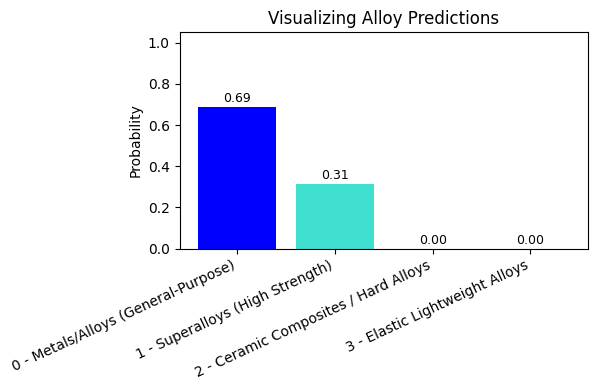

{'cluster': 0, 'label': '0 - Metals/Alloys (General-Purpose)', 'probabilities': {'0 - Metals/Alloys (General-Purpose)': 0.6881982634823358, '1 - Superalloys (High Strength)': 0.31180173645989623, '2 - Ceramic Composites / Hard Alloys': 5.2047418390073264e-54, '3 - Elastic Lightweight Alloys': 5.776801760862916e-11}}


In [31]:
# Example
example_material_4 = {
    "Tensile_Strength": 675,
    "Yield_Strength": 4245,
    "Hardness": 2250,
    "Density": 55.7,
    "Thermal_Conductivity": 1010,
    "Elasticity": 1607
}
print(predict_material_cluster(best_model, example_material_4, plot=True))

🔎 Predicting with Logistic Regression

📍 Predicted Cluster: 2 – 2 - Ceramic Composites / Hard Alloys
✅ Confidence Scores:
  - 0 - Metals/Alloys (General-Purpose): 0.3300
  - 1 - Superalloys (High Strength): 0.0000
  - 2 - Ceramic Composites / Hard Alloys: 0.6697
  - 3 - Elastic Lightweight Alloys: 0.0003


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


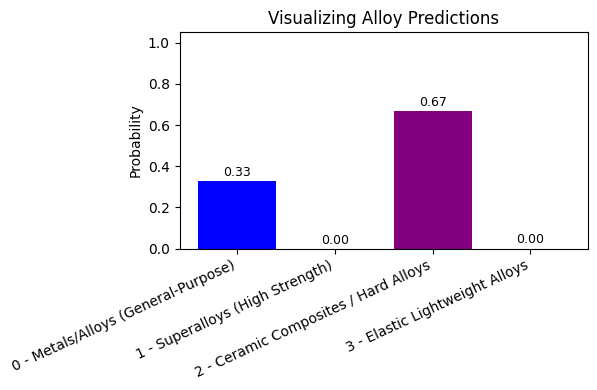

{'cluster': 2, 'label': '2 - Ceramic Composites / Hard Alloys', 'probabilities': {'0 - Metals/Alloys (General-Purpose)': 0.32995163393945426, '1 - Superalloys (High Strength)': 5.301213610357299e-08, '2 - Ceramic Composites / Hard Alloys': 0.6697016099805829, '3 - Elastic Lightweight Alloys': 0.0003467030678266824}}


In [32]:
# Example
example_material_4 = {
    "Tensile_Strength": 1777,
    "Yield_Strength": 1617,
    "Hardness": 568,
    "Density": 5.87,
    "Thermal_Conductivity": 371,
    "Elasticity": 18
}
print(predict_material_cluster(best_model, example_material_4, plot=True))

🔎 Predicting with Logistic Regression

📍 Predicted Cluster: 3 – 3 - Elastic Lightweight Alloys
✅ Confidence Scores:
  - 0 - Metals/Alloys (General-Purpose): 0.0000
  - 1 - Superalloys (High Strength): 0.2459
  - 2 - Ceramic Composites / Hard Alloys: 0.1437
  - 3 - Elastic Lightweight Alloys: 0.6104


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


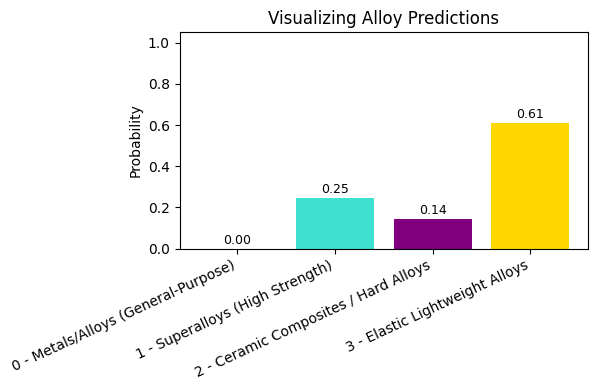

{'cluster': 3, 'label': '3 - Elastic Lightweight Alloys', 'probabilities': {'0 - Metals/Alloys (General-Purpose)': 4.5259420579549046e-17, '1 - Superalloys (High Strength)': 0.2459230147784269, '2 - Ceramic Composites / Hard Alloys': 0.14366434744753903, '3 - Elastic Lightweight Alloys': 0.610412637774034}}


In [33]:
# Example
example_material_4 = {
    "Tensile_Strength": 10,
    "Yield_Strength": 3010,
    "Hardness": 150,
    "Density": 11.7,
    "Thermal_Conductivity": 444,
    "Elasticity": 66
}
print(predict_material_cluster(best_model, example_material_4, plot=True))

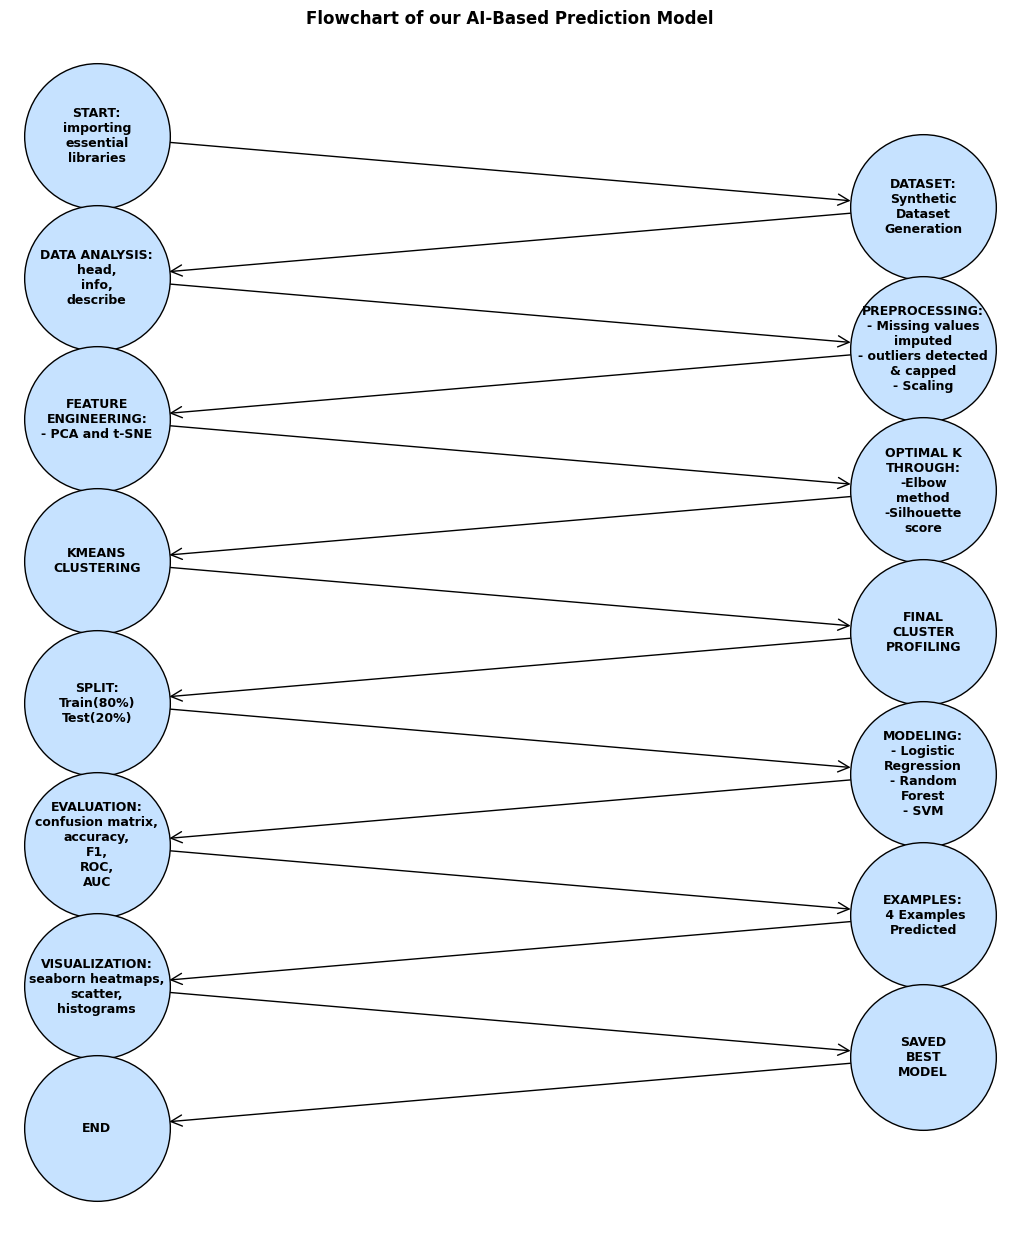

In [34]:
# 📊 Zig-Zag Flowchart
import matplotlib.pyplot as plt
import networkx as nx

# Define nodes with labels
nodes = {
    "Start": "START:\nimporting\nessential\nlibraries",
    "Dataset": "DATASET:\nSynthetic\nDataset\nGeneration",
    "Data Analysis": "DATA ANALYSIS:\nhead,\ninfo,\ndescribe",
    "Preprocessing": (
        "PREPROCESSING:\n"
        "- Missing values\nimputed\n"
        "- outliers detected\n& capped\n"
        "- Scaling"
    ),
    "Feature Engineering":"FEATURE\nENGINEERING:\n- PCA and t-SNE",
    "Optimal K":("OPTIMAL K\nTHROUGH:\n-Elbow\nmethod\n-Silhouette\nscore"),
    "K Means clustering": "KMEANS\nCLUSTERING",
    "Profiling": "FINAL\nCLUSTER\nPROFILING",
    "Split": "SPLIT:\nTrain(80%)\nTest(20%)",
    "Model": (
        "MODELING:\n"
        "- Logistic\nRegression\n"
        "- Random\nForest\n"
        "- SVM"
    ),
    "Evaluating models": "EVALUATION:\nconfusion matrix,\naccuracy,\nF1,\nROC,\nAUC",
    "Example": "EXAMPLES:\n 4 Examples\nPredicted",
    "Visualizing": "VISUALIZATION:\nseaborn heatmaps,\nscatter,\nhistograms",
    "Save": "SAVED\nBEST\nMODEL",
    "End": "END"
}

# Define order of flow
order = ["Start","Dataset","Data Analysis","Preprocessing","Feature Engineering","Optimal K","K Means clustering","Profiling","Split","Model","Evaluating models","Example","Visualizing","Save","End"]

# Build graph
G = nx.DiGraph()
for n, label in nodes.items():
    G.add_node(n, label=label)
for i in range(len(order)-1):
    G.add_edge(order[i], order[i+1])

# Assign zig-zag positions
pos = {}
for i, n in enumerate(order):
    x = (i % 2) * 1   # alternate left (0) and right (2)
    y = -i * 0.5
    pos[n] = (x, y)

# Draw
plt.figure(figsize=(10, 12))
nx.draw(
    G, pos,
    with_labels=True,
    labels=nodes,
    node_size=11000,
    node_color="#c6e2ff",
    edgecolors="black",
    font_size=9,
    font_weight="bold",
    arrows=True,
    arrowsize=20,
    arrowstyle="->"
)

plt.title("Flowchart of our AI-Based Prediction Model", fontsize=12, weight="bold")
plt.axis("off")
plt.show()